# 05 — Referências: o que cada fonte sustenta no projeto

Atualiza `Relatórios do Projeto/05_REFERENCIAS.md` (outubro/2026). Para cada referência: o que é, onde o
projeto a usa e em que estado está a citação.

## O que mudou desde o relatório de outubro

| Tema | Relatório 05 (14/10/2026) | Agora (10/11/2026) |
|---|---|---|
| Artigo de caracterização das escolas | "A2", citação "a preencher quando o artigo for lido" | **Almeida & Mussato (2023)**, com a citação completa tirada do próprio PDF (`Artigos/`). Lido e usado: 18 itens, 4 dimensões, índice e as 4 regiões da avaliação de equidade |
| Material didático Ames Housing (A1) | anotado | mantido; o PDF não está no repositório |
| Proposta do orientador | não listada | listada: é a fonte das decisões D1–D7 e D10 e da estratégia de modelagem |
| Método | Breiman, Friedman, ESL, Kuhn & Johnson | + as citadas na metodologia (Elastic Net, PR-AUC, SHAP, Molnar) e as **usadas no protocolo mas ainda não citadas** em nenhum documento (Holm, bootstrap, Ridge, árvore) |
| Contexto (abandono, TDI, Pé-de-Meia) | "a preencher" | as referências que o Plano avançado (07/10) cita, **a conferir** antes de usar |

**Estados:**

- **citada nos documentos:** já aparece no `CLAUDE.md`, na metodologia ou nos relatórios;
- **sugerida:** o projeto usa o método, mas nenhum documento cita a fonte;
- **indireta:** lida só através da lista de referências de Almeida & Mussato;
- **a conferir:** citada pelo Plano avançado sem a referência completa.

A classificação está em `registros/referencias.csv`, uma linha por referência.

In [1]:
import sys
from pathlib import Path

AQUI = Path.cwd()                                  # o notebook roda de Dados-do-Projeto/Contexto do Projeto
if not (AQUI / "gerar_tabelas.py").exists():
    raise FileNotFoundError(f"Abra este notebook de dentro de Dados-do-Projeto/Contexto do Projeto (pasta atual: {AQUI})")
DADOS_DO_PROJETO = AQUI.parent
OFICIAL = DADOS_DO_PROJETO / "abandono-escolar"    # junction para Pmonkey/abandono-escolar
GUSTAVO = DADOS_DO_PROJETO / "gustavo"
sys.path.insert(0, str(OFICIAL))
sys.path.insert(0, str(AQUI))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import desenho as D
from src import figuras as F

print(F.conferir_ambiente(OFICIAL / "requirements.txt"))
F.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 30)
TABELAS = AQUI / "tabelas"                         # python gerar_tabelas.py
FIGURAS = AQUI / "figuras"


def figura_existente(caminho, largura=820):
    """Mostra uma figura gerada por outro notebook (não a recalcula)."""
    F.exigir({caminho.name: caminho}, como_gerar="executar o notebook que a gera (ver a legenda)")
    display(Image(filename=str(caminho), width=largura))

{'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.1'}


In [2]:
ENTRADAS = {
    "referencias": AQUI / "registros" / "referencias.csv",        # escrito à mão, uma linha por referência
    "por_parte": TABELAS / "referencias_por_parte.csv",           # gerar_tabelas.py
    "resumo": TABELAS / "registros_resumo.csv",                   # gerar_tabelas.py
}
F.exigir(ENTRADAS, como_gerar='python "Contexto do Projeto/gerar_tabelas.py"')
refs = pd.read_csv(ENTRADAS["referencias"], keep_default_na=False)
por_parte = pd.read_csv(ENTRADAS["por_parte"])
resumo = pd.read_csv(ENTRADAS["resumo"], keep_default_na=False)
pd.set_option("display.max_colwidth", 220)

## 1. Mapa: que parte do projeto cada grupo de referências sustenta

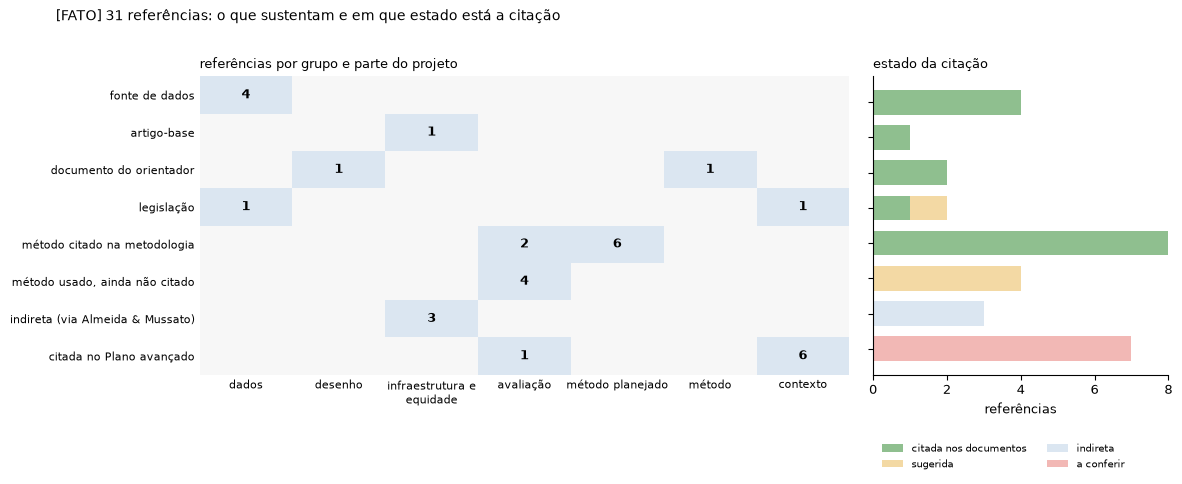

In [3]:
grupos = list(dict.fromkeys(refs["grupo"]))
partes = ["dados", "desenho", "infraestrutura e equidade", "avaliação", "método planejado", "método", "contexto"]
mat = por_parte.pivot(index="grupo", columns="parte", values="referencias").reindex(index=grupos, columns=partes)
est = resumo[resumo["registro"] == "referencias"].pivot(index="grupo", columns="estado", values="n").reindex(grupos).fillna(0)
ordem_est = [e for e in ["citada nos documentos", "sugerida", "indireta", "a conferir"] if e in est.columns]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
from matplotlib.colors import ListedColormap
a1.imshow(mat.notna().to_numpy(dtype=float), cmap=ListedColormap(["#f7f7f7", D.AZUL_CLARO]),
          aspect="auto", vmin=0, vmax=1)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.iat[i, j]
        if pd.notna(v):
            a1.text(j, i, f"{int(v)}", ha="center", va="center", fontsize=9, fontweight="bold")
a1.set_xticks(range(len(partes)), [p.replace(" e ", " e\n") for p in partes], fontsize=8)
a1.set_yticks(range(len(grupos)), grupos, fontsize=8)
a1.tick_params(length=0)
for lado in ("top", "right", "bottom", "left"):
    a1.spines[lado].set_visible(False)
a1.set_title("referências por grupo e parte do projeto", loc="left", fontsize=9)
esquerda = pd.Series(0.0, index=grupos)
for e in ordem_est:
    a2.barh(range(len(grupos)), est[e], left=esquerda, color=D.COR_ESTADO[e], label=e, height=0.7)
    esquerda = esquerda + est[e]
a2.set_yticks(range(len(grupos)), [])
a2.invert_yaxis()
a2.set_xlabel("referências")
a2.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(0.0, -0.2), ncol=2)
a2.set_title("estado da citação", loc="left", fontsize=9)
F.titulo_figura(fig, f"{len(refs)} referências: o que sustentam e em que estado está a citação", "FATO")
fig.subplots_adjust(top=0.82, wspace=0.05)
F.salvar(fig, FIGURAS, "05_mapa_referencias")
plt.show()

## 2. O artigo-base: Almeida & Mussato (2023)

> ALMEIDA, Diego Araújo de; MUSSATO, Solange. Índice de infraestrutura das escolas estaduais de ensino médio
> de Roraima e as desigualdades territoriais. **Pesquisa e Debate em Educação**, Juiz de Fora: UFJF, v. 13,
> p. 1-18, e35603, 2023. ISSN 2237-9444. DOI: https://doi.org/10.34019/2237-9444.2023.v13.35603.

PDF em `Dados-do-Projeto/Artigos/ALMEIDA & MUSSATO.pdf`. Os autores são da Secretaria de Estado da Educação e
Desporto de Roraima, o que faz deles um interlocutor natural para a avaliação de equidade.

**O que o artigo fez** (números do próprio artigo, não do projeto):

- 165 escolas estaduais de Roraima com ensino médio, Censo Escolar 2019.
- **18 variáveis dicotômicas** (presença ou ausência) em **4 dimensões** (Quadro 3):
  - infraestrutura básica (IIB): água potável, energia da rede pública, coleta de lixo, banheiro;
  - dependências administrativas (IDA): despensa, refeitório, sala da diretoria, sala dos professores,
    secretaria;
  - dependências pedagógicas (IDP): biblioteca, laboratório de informática, pátios, quadra;
  - equipamentos pedagógicos (IEP): computador, impressora, projetor, internet.
- Cada dimensão é a soma simples dos itens, padronizada nas 165 escolas. O **índice de infraestrutura
  escolar (IIE)** é a primeira componente principal das 4 dimensões.
- As escolas foram agrupadas em **4 regiões** (Quadro 2):

  | Região | Descrição | Escolas |
  |---|---|---|
  | Capital | estaduais urbanas de Boa Vista | 38 |
  | Interior_A | estaduais urbanas fora de Boa Vista | 19 |
  | Interior_B | estaduais rurais não indígenas | 37 |
  | Indígena | estaduais rurais indígenas | 71 |

- **Resultado:** a Capital tem a melhor infraestrutura e a menor desigualdade, seguida do Interior_A, do
  Interior_B e das escolas indígenas. Há desigualdade também dentro de cada região.

**Como o projeto usa o artigo:**

| Uso | No artigo | No projeto | Onde |
|---|---|---|---|
| Itens e dimensões | 18 itens, 4 dimensões, Censo 2019 | os mesmos 18 itens, **todas as escolas de RR na base, 2007–2025**. Regra de fonte: a primeira coluna realmente coletada, senão `NaN`. Substitutos antes de 2019 (água filtrada, banheiro dentro do prédio, biblioteca/sala de leitura em 2007–08, retroprojetor até 2011) | `gustavo/programas/03`, relatórios 04–05 do Gustavo |
| Padronização e índice | z nas 165 escolas de 2019; ACP | **z dentro de cada ano** (`zano`) e PC1 por ano. Os pesos fixos de 2019 (`zref19`) foram descartados porque usariam dado futuro nas dobras anteriores a 2019 | `gustavo/programas/05`; relatório 05, §3 |
| Itens ausentes no início da série | — | em 2007–2011, IDA com 2 itens e IDP com 3; concordância com a versão completa de 0,89–0,93 (dimensões) e 0,99 (IIE) | relatório 05, §5 |
| Regiões | 4 regiões das escolas estaduais de EM | os **estratos da avaliação de equidade**: capital, interior urbano, interior rural não indígena, indígena. Dependem de `IN_EDUCACAO_INDIGENA` e `TP_LOCALIZACAO_DIFERENCIADA` (D8, em aberto) | `CLAUDE.md` §1 |
| Resultado | caracteriza desigualdade | a infraestrutura **não carrega sinal para priorizar o abandono do ano seguinte** (0 de 8 testes; notebook 04). Não contradiz o artigo, que mede desigualdade e não prevê abandono. Fica como estratificação | `DECISOES.md` 2026-11-02 |

**Pendência registrada:** reproduzir a Tabela 1 do artigo. O recorte de referência de 2019 tem **152
escolas** no `gustavo/`, contra 165 no artigo. A diferença são escolas fora da base de rendimento, e
reproduzir exigiria as colunas de filtro e a de escola indígena do Censo 2019 (`gustavo/README.md`,
pendências).

**Referências que o artigo usa e que servem à seção de infraestrutura do texto do projeto** (lidas só pela
lista do artigo):

In [4]:
refs[refs["grupo"].str.startswith("indireta")][["referencia", "uso_no_projeto"]].set_index("referencia")

,uso_no_projeto
referencia,
"ALVES, Maria Teresa Gonzaga; XAVIER, Flavia Pereira; PAULA, Túlio Silva de. Modelo conceitual para avaliação da infraestrutura escolar no ensino fundamental. Revista Brasileira de Estudos Pedagógicos, Brasília, v. 100, n. 255, 2019.",modelo conceitual de infraestrutura adotado pelo artigo-base
"SOARES NETO, Joaquim José; JESUS, Girlene Ribeiro de; KARINO, Camila Akemi; ANDRADE, Dalton Francisco de. Uma escala para medir a infraestrutura escolar. Estudos em Avaliação Educacional, São Paulo, v. 24, n. 54, p. 78-99, 2013.",escala de infraestrutura escolar a partir do Censo
"SÁTYRO, Natália; SOARES, Sergei. A infraestrutura das escolas brasileiras de ensino fundamental: um estudo com base nos censos escolares de 1997 a 2005. Brasília: IPEA, 2007 (Texto para Discussão, n. 1267).",série longa de infraestrutura no Censo


## 3. A proposta do orientador

> FIGUEIREDO, Bruno Cesar Barreto. Proposta detalhada de análise preditiva do abandono escolar em Roraima e
> base longitudinal v1.0. UERR, 17 set. 2026. (`abandono-escolar/docs/README.md` e
> `docs/Proposta_Detalhada_Analise_Preditiva_Abandono_Escolar_Roraima.pdf`)

É a fonte das decisões de desenho (D1–D7 e D10) e da metodologia (`docs/metodologia_variaveis.md`, escrita a
partir dela). O que cada seção do README sustenta:

| Seção | Conteúdo | No projeto |
|---|---|---|
| §7 Semântica temporal | preditores de *t*, desfecho de *t*+1; os `*_T1` nunca como preditor; uso para planejar o ano seguinte | regra 4; Cenário B |
| §8 Ausentes | ausente não vira zero; não imputar IED de 2019–2020; versões com e sem IED | regra 5; o bloco 3 (IED) separado |
| §9 Validações | chave única, taxas em 0–100, trio fecha em 100, IED soma 100, 6 escolas mudam de localização, 105 de nome | refeitas por `assert` (critério 3) |
| §10 Estratégia de modelagem | 10 passos | o estado de cada um está no notebook 07 |
| §11 2020–2021 | todos os anos, sensibilidade, variável de período | D6 (S1–S4, não rodadas) |
| §12 Limitações | agregado por escola; abandono não é evasão; anual; IED só de 2021; associação, não causa | `CLAUDE.md` §1 (vocabulário) |
| §13 Enriquecimento | porte, composição, tempo integral, EJA, infraestrutura, docentes, turmas, contexto territorial | infraestrutura feita; o resto proposto (D8) ou suspenso (Fase 3) |
| §14 Atualização futura | 2026 entra como ano sem desfecho; repetir as validações; nunca sobrescrever | notebook 07 |
| §15 Governança | base derivada; congelar a versão e registrar o hash | manifesto sha256; regra 1 |
| Responsabilidade analítica | não usar para classificar escolas nem responsabilizar profissionais | uso pretendido do `CLAUDE.md` §1 |

## 4. Material didático: Ames Housing

> FIGUEIRÊDO, Bruno Cesar Barreto. **Estimação de Preços de Imóveis com Machine Learning: Um Estudo Completo
> com o Dataset Ames Housing.** Material didático. UERR, set. 2026.

Serve de **referência de vocabulário de pipeline**, não de resultado. Usa-se a estrutura EDA → limpeza →
atributos → modelagem → avaliação, o `ColumnTransformer` + `Pipeline` e as definições de MAE, RMSE e R². Não
se usam o conjunto de dados nem a conclusão "a regressão linear venceu a floresta", que vale para aqueles
dados. O relatório de outubro diz que o PDF estaria em `A1_ames_housing_didatico.pdf`, mas esse arquivo
**não está em nenhum dos dois repositórios**: guardar em `Artigos/` se for citado.

## 5. Fontes de dados

In [5]:
refs[refs["grupo"].isin(["fonte de dados", "legislação"])][["referencia", "uso_no_projeto", "estado"]].set_index("referencia")

,uso_no_projeto,estado
referencia,,
BRASIL. Instituto Nacional de Estudos e Pesquisas Educacionais Anísio Teixeira (Inep). Microdados do Censo Escolar da Educação Básica 2019–2025. Brasília: Inep. Acesso em: 2 a 15 set. 2026.,18 itens de infraestrutura; funil Brasil → RR; candidatos da D8,citada nos documentos
"BRASIL. Inep. Indicadores Educacionais: Taxas de Rendimento, Distorção Idade-série, Alunos por Turma, Esforço Docente e Horas-aula diária, 2019–2025. Brasília: Inep. Acesso em: 9 a 17 set. 2026.","desfecho (tx_rend) e preditores (TDI, ATU, IED)",citada nos documentos
INEP. Notas técnicas dos indicadores educacionais (rodapés das planilhas) e Nota técnica do indicador de esforço docente (2014).,"definições e fórmulas de TDI, ATU e IED",citada nos documentos
INEP. Nota sobre as tabulações de docentes por escola deslocadas em 2007–2021 (dados/origem/doc/Nota-2021.pdf).,P011: QT_DOC_* de 2019–2021 só com conferência de plausibilidade,citada nos documentos
"BRASIL. Lei nº 11.274, de 6 de fevereiro de 2006. Ensino fundamental de nove anos.",ruptura possível em 2007–2010 na série estendida (8 → 9 anos),citada nos documentos
"BRASIL. Lei nº 12.527, de 18 de novembro de 2011. Lei de Acesso à Informação.",base legal do uso de dados públicos,sugerida


**Como citar uma versão do INEP.** O INEP republica arquivos sem aviso (notebook 02, §2): o Censo 2024 é a
versão `_defeso` e o de 2025 é `_v2`. Por isso, no artigo, vale citar a **data de acesso** e indicar que a
versão exata está fixada pelo sha256 do `dados/MANIFEST.csv`. Sem isso, outra pessoa pode baixar um arquivo
diferente com o mesmo nome. Isto é uma sugestão de redação, não uma decisão registrada.

## 6. Método

In [6]:
refs[refs["grupo"].str.startswith("método")][["grupo", "referencia", "uso_no_projeto", "estado"]].set_index("referencia")

,grupo,uso_no_projeto,estado
referencia,,,
"ZOU, Hui; HASTIE, Trevor. Regularization and variable selection via the elastic net. Journal of the Royal Statistical Society: Series B, v. 67, n. 2, p. 301-320, 2005.",método citado na metodologia,Elastic Net (E1); no protocolo só há o Ridge,citada nos documentos
"BREIMAN, Leo. Random forests. Machine Learning, v. 45, n. 1, p. 5-32, 2001.",método citado na metodologia,"E3, não rodado no protocolo; usado no exploratório da P026",citada nos documentos
"FRIEDMAN, Jerome H. Greedy function approximation: a gradient boosting machine. The Annals of Statistics, v. 29, n. 5, p. 1189-1232, 2001.",método citado na metodologia,"E4, não rodado",citada nos documentos
"SAITO, Takaya; REHMSMEIER, Marc. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. PLOS ONE, v. 10, n. 3, e0118432, 2015.",método citado na metodologia,PR-AUC para os desfechos binários (não rodados),citada nos documentos
"LUNDBERG, Scott M.; LEE, Su-In. A unified approach to interpreting model predictions. In: Advances in Neural Information Processing Systems 30 (NeurIPS 2017).",método citado na metodologia,SHAP (não usado),citada nos documentos
"MOLNAR, Christoph. Interpretable Machine Learning. 2. ed., 2022.",método citado na metodologia,explicabilidade; importância por permutação,citada nos documentos
"HASTIE, Trevor; TIBSHIRANI, Robert; FRIEDMAN, Jerome. The Elements of Statistical Learning. 2. ed. New York: Springer, 2009.",método citado na metodologia,referência geral de método,citada nos documentos
"KUHN, Max; JOHNSON, Kjell. Feature Engineering and Selection: A Practical Approach for Predictive Models. Boca Raton: CRC Press, 2019.",método citado na metodologia,seleção de variáveis sem olhar o desfecho (regra 3),citada nos documentos
"HOLM, Sture. A simple sequentially rejective multiple test procedure. Scandinavian Journal of Statistics, v. 6, n. 2, p. 65-70, 1979.","método usado, ainda não citado",correção de Holm nas famílias F1–F5,sugerida


**Usadas e ainda não citadas.** O protocolo de 02/11 usa a correção de Holm, o bootstrap por percentis, o
Ridge e a árvore de regressão, mas nenhum documento cita as fontes desses métodos. As referências listadas
como "sugerida" são as clássicas de cada um. Revisar antes de levar ao artigo.

## 7. Contexto: o que o Plano avançado cita (a conferir)

O Plano avançado de 07/10 (notebook 07) cita trabalhos que dialogam com os achados do projeto:

- previsibilidade baixa de desfechos sociais;
- direcionamento pela escola em sistemas de alerta;
- ruído de escola pequena;
- alertas por frequência com sorteio.

O plano traz só autor, ano e veículo. **Nenhuma dessas referências foi conferida** nesta revisão.

In [7]:
refs[refs["grupo"] == "citada no Plano avançado"][["referencia", "uso_no_projeto", "onde"]].set_index("referencia")

,uso_no_projeto,onde
referencia,,
"Salganik et al. (2020), PNAS.",previsibilidade baixa de desfechos sociais: modelos pouco acima de um baseline simples,"Plano avançado (07/10), p. 5"
Perdomo et al. (2023).,sistema de alerta de Wisconsin: direcionar pela escola tão eficiente quanto o escore individual,"Plano avançado (07/10), p. 5"
"Andrade e Soida (2015), Estudos Econômicos.",rankings de escolas pequenas oscilam e persistem pouco,"Plano avançado (07/10), p. 5"
Kane e Staiger (2002).,ruído de escola pequena e regressão à média,"Plano avançado (07/10), p. 5"
"Cossi et al. (2024), BID.",Sergipe: regras simples de frequência avaliadas com sorteio de 299 escolas,"Plano avançado (07/10), p. 6"
Checklist REFORMS (recomendações para ciência baseada em aprendizado de máquina).,proposto como checklist do protocolo (trilha T0),"Plano avançado (07/10), p. 8"
"Centro de Evidências da Educação Integral (Insper e parceiros), estudo sobre o Pé-de-Meia, mar. 2026.",simulação prévia; avaliação com resultados observados só a partir do 4º ano,"Plano avançado (07/10), p. 10–11"


## 8. Política para os PDFs

- Os artigos originais ficam em **PDF**, em `Dados-do-Projeto/Artigos/`. Hoje só há o de Almeida & Mussato.
- **Não converter PDF em markdown:** perde fórmula, figura, tabela e a referência correta. O PDF é o original;
  este notebook é a anotação.
- Ao citar uma referência no artigo, guardar o PDF na pasta e mudar o estado dela em
  `registros/referencias.csv` para "citada nos documentos".